Now that the selected enzyme classes are cleaned, I want to look at the proteins to help determine what type of classifier I should use. 

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

proj_path = Path.cwd().parent 

hydrolases_cleaned = pd.read_csv(proj_path / "data" / "CleanedSequences" / "HydrolasesCleaned.csv")
transferases_cleaned = pd.read_csv(proj_path / "data" / "CleanedSequences" / "TransferasesCleaned.csv")

hydrolases_sample = hydrolases_cleaned.sample(2000,random_state=42)
transferases_sample = transferases_cleaned.sample(2000,random_state=42)




With the loaded sequences

In [ ]:
from Bio.SeqUtils.ProtParam import ProteinAnalysis

hydrolases_sample["AA Content"] = hydrolases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).amino_acids_percent)
transferases_sample["AA Content"] = transferases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).amino_acids_percent)

hydrolases_sample["SS Fraction"] = hydrolases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).secondary_structure_fraction())
transferases_sample["SS Fraction"] = transferases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).secondary_structure_fraction())
    
hydrolases_sample["MW"] = hydrolases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).molecular_weight())
transferases_sample["MW"] = transferases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).molecular_weight())

hydrolases_sample["Flexability"] = hydrolases_sample["Sequence"].apply(lambda x: np.mean(ProteinAnalysis(x).flexibility()))
hydrolases_sample["Flexability"] = transferases_sample["Sequence"].apply(lambda x: np.mean(ProteinAnalysis(x).flexibility()))

hydrolases_sample["GRAVY"] = hydrolases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).gravy())
transferases_sample["GRAVY"] = transferases_sample["Sequence"].apply(lambda x: ProteinAnalysis(x).gravy())

for amino_acid in "ACDEFGHIKLMNPQRSTVWY":
    hydrolases_sample[f"{amino_acid}"] = hydrolases_sample["AA Content"].apply(lambda x: x.get(amino_acid,0))
    transferases_sample[f"{amino_acid}"] = transferases_sample["AA Content"].apply(lambda x: x.get(amino_acid,0))

secondary_structures = ["Helix","Turn","Sheet"]
for feature in range(3):
    hydrolases_sample[f"{secondary_structures[feature]}"] = hydrolases_sample["SS Fraction"].apply(lambda x: x[feature])
    transferases_sample[f"{secondary_structures[feature]}"] = transferases_sample["SS Fraction"].apply(lambda x: x[feature])

print(hydrolases_sample.columns)


In [ ]:
%matplotlib widget
import seaborn as sns 
import matplotlib.pyplot as plt


ax = plt.figure(1).add_subplot(projection="3d")
ax.scatter(hydrolases_sample["SS Fraction"].str[0],hydrolases_sample["SS Fraction"].str[1],hydrolases_sample["SS Fraction"].str[2],s=0.5,c="red",alpha=0.5)
ax.scatter(transferases_sample["SS Fraction"].str[0],transferases_sample["SS Fraction"].str[1],transferases_sample["SS Fraction"].str[2],s=0.5,c="blue",alpha=0.5)
plt.show()

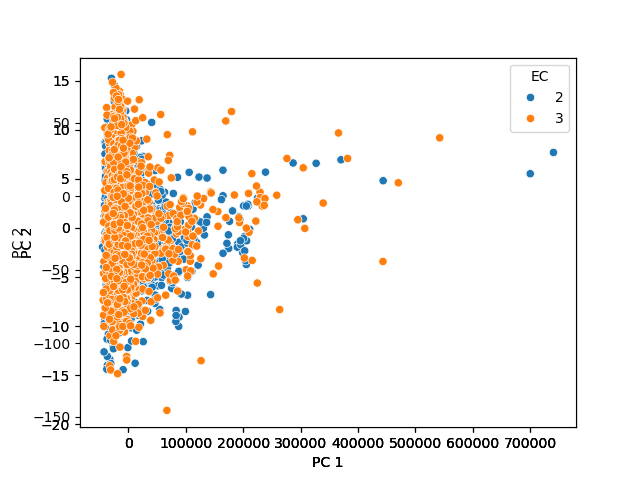

In [6]:
from sklearn.decomposition import PCA

both_classes = pd.concat([hydrolases_sample,transferases_sample])

protein_PCA = PCA(n_components=2,random_state=42).fit_transform(both_classes.iloc[:,9:].to_numpy(na_value=0))

both_classes["EC"] = ["2" for i in range(2000)] + ["3" for i in range(2000)]
both_classes["PC 1"] = protein_PCA[:,0]
both_classes["PC 2"] = protein_PCA[:,1]

ax2 = plt.figure(2).add_subplot()

sns.scatterplot(both_classes,x="PC 1",y="PC 2",hue="EC",ax=ax2)
plt.show()

Not enough 

In [7]:
from itertools import product


def kmers_freq(seq,k):
    kmers = product("ACDEFGHIKLMNPQRSTVWY",repeat=k)
    freq = {0 for kmer in kmers}
    for i in range(len(seq) - k + 1):
        kmer = seq[i:i+k]
        if kmer in freq:
            freq[kmer] += 1
    total = sum(freq.values()) or 1
    return [v / total for v in freq.values()]



SyntaxError: incomplete input (3185232094.py, line 3)